In [1]:
import warnings
import os 
from pathlib import Path
from natsort import natsort_keygen

import pandas as pd
from pathlib import Path
import anndata as ad 
import numpy as np 
from dotenv import dotenv_values

import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

warnings.simplefilter(action='ignore', category=FutureWarning)
plt.rcParams["pdf.fonttype"] = 42

In [2]:
# Setting up filepaths from config
CONFIG = dotenv_values("config.env") 
DATADIR = Path(CONFIG['DATADIR'])

OUTDIR = DATADIR / "publication" / "Fig_03"
os.makedirs(OUTDIR, exist_ok=True)

SC_IN_FP = DATADIR / "9_objects" / "singlecell" / 'hypomap3d_singlecell_control.h5ad'
RM_FP = DATADIR / "9_objects" / "spatial" / "regionwise_relative_masses" / "regionwise_relative_masses_wo_fibers.csv" # this file was used for region assignment
OVERVIEW_FP = OUTDIR / "dmh_cluster_overview.tsv"

In [3]:
adata = ad.read_h5ad(SC_IN_FP, backed="r")

In [4]:
dmh_cluster_overview = pd.read_csv(OVERVIEW_FP, delimiter="\t")

# manually overwriting some of the colors
color_mapping_L2 = {
 'Gl2-26': '#F781BF',
 'Gl2-25': '#B05B3A' ,
 'Gl2-11': '#E8D430',
 'Gl2-36': '#58386e',
 'Gb2-64': '#CB6651',
 'Gb2-57': '#FFAF13',
 'Gb2-54': "#47A265",
 'Gb2-49': '#4C71A4',
 'Gb2-43': "#E41A1C"
 }

dmh_cluster_overview["L2_ID"] = dmh_cluster_overview.L2_descr.apply(lambda x: x.split(" ")[0])
dmh_cluster_overview.color_L2 = dmh_cluster_overview.L2_ID.map(color_mapping_L2)

color_mapping_L2 = dmh_cluster_overview.loc[:, ["L2_descr", "color_L2"]].drop_duplicates().set_index("L2_descr").to_dict()["color_L2"]

dmh_cluster_overview.head(3)

,L3_ID,L3_descr,L2_descr,region_rank,relative_mass,cum_mass,flag,color_L3,color_L2,L2_ID
0,Gl3-84,Gl3-84 DMH Nr2f1,Gl2-26 DMH Nkx2-4,1,0.256136,0.000000,NaN,#518C55,#F781BF,Gl2-26
1,Gl3-83,Gl3-83 DMH Pdyn,Gl2-26 DMH Nkx2-4,1,0.287700,0.000000,NaN,#8AA716,#F781BF,Gl2-26
2,Gl3-82,Gl3-82 VMH Npy2r,Gl2-25 DMH Hmx2,3,0.149167,0.385678,NaN,#8A823C,#B05B3A,Gl2-25


In [5]:

subclasses = dmh_cluster_overview.L2_descr.unique()

In [6]:
dmh_cluster_overview.head(2)

,L3_ID,L3_descr,L2_descr,region_rank,relative_mass,cum_mass,flag,color_L3,color_L2,L2_ID
0,Gl3-84,Gl3-84 DMH Nr2f1,Gl2-26 DMH Nkx2-4,1,0.256136,0.0,NaN,#518C55,#F781BF,Gl2-26
1,Gl3-83,Gl3-83 DMH Pdyn,Gl2-26 DMH Nkx2-4,1,0.287700,0.0,NaN,#8AA716,#F781BF,Gl2-26


In [7]:
labelmat = adata.obs.loc[adata.obs.L2_descr.isin(subclasses), [f"L{i}_descr" for i in range(1,6)]].drop_duplicates()
l3_to_l2 = labelmat.set_index("L3_descr").to_dict()["L2_descr"]
labelmat.head(2)

,L1_descr,L2_descr,L3_descr,L4_descr,L5_descr
SC1-01_SAMN18754353_AACCATGTCAGAGTGG,Gb1-2 GABA,Gb2-43 DMH-LHA Gsx1,Gb3-145 ARH Ghrh,Gb4-387 ARH Ghrh,Gb5-520 ARH Ghrh.Fgl2
SC1-01_SAMN18754353_AATCACGTCATGCCAA,Gb1-2 GABA,Gb2-49 DMH Hmx2.Lef1,Gb3-170 DMH Tac2,Gb4-469 DMH Tac2.Npbwr1,Gb5-623 DMH Tac2.Npbwr1


# Preparing data and prototyping parts of the combined cluster tree plots

## Dendrogram 

### Let's build the linkage

In [8]:
def build_custom_linkage(df, level_cols):
    """
    Build a custom linkage matrix Z from a DataFrame using specified hierarchical columns.
    Supports 2 levels of hierarchy.

    Parameters:
        df: pd.DataFrame
        level_cols (list of str): List of column names defining the hierarchy from top to bottom.

    Returns:
        tuple:
            Z (np.ndarray): linkage matrix for dendrogram.
            idx_to_label (dict): mapping from leaf index to bottom-level cluster label.
    """
    assert 2 <= len(level_cols), "Function supports 2 levels of hierarchy"
    
    # Drop duplicates and sort
    df = df[level_cols].drop_duplicates().astype(str)

    key = natsort_keygen()
    df = df.sort_values(
        by=level_cols,
        key=lambda col: col.map(key)
    )

    # sort Gl before Gb or NN
    df = pd.concat([
        df.loc[df[level_cols[0]].str.contains("Gl")],
        df.loc[df[level_cols[0]].str.contains("Gb")],
        df.loc[df[level_cols[0]].str.contains("NN")]
    ], axis=0
    )

    bottom_col = level_cols[-1]
    bottom_clusters = df[bottom_col].unique()
    n_leaves = len(bottom_clusters)

    cluster_sizes = {}
    Z = []
    current_idx = 0
    merge_map = {}

    # Map bottom level clusters to leaf indices
    bottom_to_idx = {name: i for i, name in enumerate(bottom_clusters)}
    idx_to_label = {i: name for i, name in enumerate(bottom_clusters)}
    cluster_sizes = {i: 1 for i in range(n_leaves)}
    current_idx = n_leaves

    # Recursive merging from bottom-up
    for level in reversed(range(1, len(level_cols))):  # Start from second last to top
        parent_col = level_cols[level - 1]
        child_col = level_cols[level]

        merge_map_level = {}
        for parent, group in df.groupby(parent_col):
            child_clusters = group[child_col].unique()
            leaves = [
                merge_map.get(child, bottom_to_idx.get(child))
                for child in child_clusters
            ]

            # Merge all clusters under this parent
            while len(leaves) > 1:
                a = leaves.pop()
                b = leaves.pop()
                size_a = cluster_sizes[a]
                size_b = cluster_sizes[b]
                new_size = size_a + size_b
                Z.append([a, b, 0.2 + 0.1 * level, new_size])  # Distance increases with hierarchy
                cluster_sizes[current_idx] = new_size
                leaves.append(current_idx)
                current_idx += 1

            merge_map_level[parent] = leaves[0]  # Store representative for parent cluster
        merge_map = merge_map_level

    # Final root merge if needed
    final_clusters = list(merge_map.values())
    while len(final_clusters) > 1:
        a = final_clusters.pop()
        b = final_clusters.pop()
        size_a = cluster_sizes[a]
        size_b = cluster_sizes[b]
        new_size = size_a + size_b
        Z.append([a, b, 1.0, new_size])
        cluster_sizes[current_idx] = new_size
        final_clusters.append(current_idx)
        current_idx += 1

    Z = np.array(Z)
    assert Z.shape[0] + 1 == n_leaves, f"Linkage matrix Z has incorrect shape: merges={Z.shape[0]}, leaves={n_leaves}"

    return Z, idx_to_label


In [9]:
Z_supertype, idx_to_l3 = build_custom_linkage(labelmat, [f"L{i}_descr" for i in range(2,4)])
n_leaves_supertype = labelmat.L3_descr.nunique()

### Let's get a color map

In [ ]:
def propagate_colors_to_deepest_level(df, level_cols, source_level_idx, cluster_color_map, default_color="#A0A0A0"):
    """
    Propagate colors from a specified source level to the deepest level in a hierarchy.

    Parameters:
        df (pd.DataFrame): DataFrame with hierarchical cluster levels as columns.
        level_cols (list of str): Ordered list of columns from top to bottom levels.
        source_level_idx (int): Index in level_cols of the source level (e.g., 0 for top).
        cluster_color_map (dict): Mapping from source level cluster names to colors.
        default_color (str): Default color to use if no mapping is found.

    Returns:
        dict: Mapping from deepest level cluster names to propagated colors.
    """
    assert 2 <= len(level_cols), "Supports 2 hierarchy levels"
    assert 0 <= source_level_idx < len(level_cols), "Invalid source level index"

    # Keep only relevant columns for mapping
    source_col = level_cols[source_level_idx]
    target_col = level_cols[-1]  # deepest level
    df_clean = df[[source_col, target_col]].drop_duplicates().astype(str)

    # Build mapping: deepest level → source level
    deep_to_source = dict(zip(df_clean[target_col], df_clean[source_col]))

    # Propagate color from source level to deepest
    deep_to_color = {
        deep: cluster_color_map.get(source, default_color)
        for deep, source in deep_to_source.items()
    }

    return deep_to_color


In [11]:
l3_to_color = propagate_colors_to_deepest_level(
    labelmat,
    level_cols=["L2_descr", "L3_descr"],
    source_level_idx=0, # propagate from 0 to last index
    cluster_color_map=color_mapping_L2
)


### Let's plot

In [12]:
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram

def plot_colored_dendrogram(Z, idx_to_label, leaf_label_to_color, linewidth=1.5, default_color="#000000", **kwargs):
    """
    Plots a dendrogram with colored branches based on leaf label to color mapping.

    Parameters:
        Z (np.ndarray): Linkage matrix.
        idx_to_label (dict): Mapping from leaf index to cluster label.
        leaf_label_to_color (dict): Mapping from cluster label to color.
        linewidth (float): Width of the dendrogram lines.
        default_color (str): Color to use when multiple colors are found under a branch.
        kwargs: Additional keyword arguments passed to scipy dendrogram.
    
    Returns:
        dict: The dendrogram object returned by scipy.cluster.hierarchy.dendrogram.
    """

    # Step 1: Build leaf index to color map
    leaf_colors = {
        i: leaf_label_to_color.get(idx_to_label[i], default_color)
        for i in idx_to_label
    }

    # Step 2: Helper to trace leaves under a node
    def trace_leaves(node):
        if node < len(idx_to_label):  # It's a leaf
            return {node}
        else:
            left = int(Z[node - len(idx_to_label), 0])
            right = int(Z[node - len(idx_to_label), 1])
            return trace_leaves(left) | trace_leaves(right)

    # Step 3: Determine color for each internal node
    link_colors = {}
    for i in range(Z.shape[0]):
        a, b = int(Z[i, 0]), int(Z[i, 1])
        leaves = trace_leaves(a) | trace_leaves(b)
        colors = {leaf_colors[leaf] for leaf in leaves}
        link_colors[i + len(idx_to_label)] = (
            colors.pop() if len(colors) == 1 else default_color
        )

    # Step 4: Plot with link color function
    with plt.rc_context({'lines.linewidth': linewidth}):
        dendro = dendrogram(
            Z,
            link_color_func=lambda k: link_colors.get(k, default_color),
            labels=[idx_to_label[i] for i in range(len(idx_to_label))],
            leaf_rotation=90,
            **kwargs
        )

    return dendro


In [13]:
dmh_clusters_l3 = dmh_cluster_overview.L3_descr.unique()

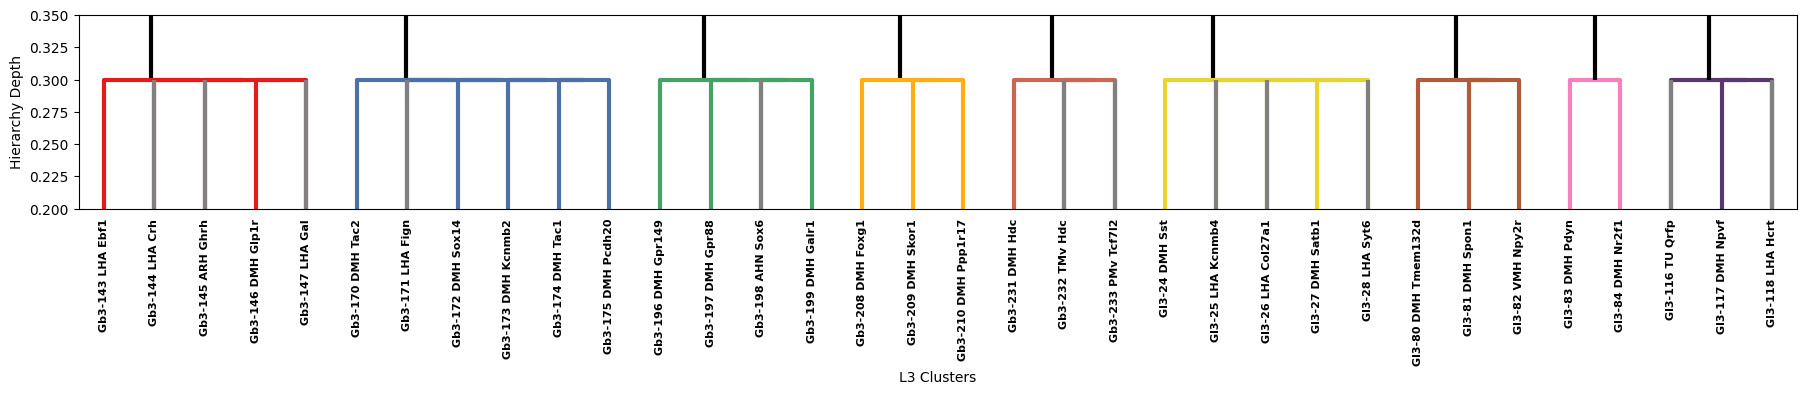

<Figure size 640x480 with 0 Axes>

In [14]:
plt.figure(figsize=(18, 4))
dendro_supertype = plot_colored_dendrogram(Z_supertype, idx_to_l3, l3_to_color, linewidth=3)

plt.xlabel("L3 Clusters")
plt.ylabel("Hierarchy Depth")
plt.xticks(fontweight='bold')
plt.tight_layout()
plt.ylim(0.2, 0.35)


# === Get label positions from x-axis tick labels ===# After plotting dendrogram
ax = plt.gca()
tick_labels = [tick.get_text() for tick in ax.get_xticklabels()]
tick_positions = ax.get_xticks()

label_to_x = {
    label: xpos for label, xpos in zip(tick_labels, tick_positions)
}

for label in label_to_x.keys():
    if label not in dmh_clusters_l3:
        plt.vlines(x=label_to_x[label], 
                ymin = 0, ymax=0.3,
                color="grey", linestyle='-', linewidth=3)


plt.gca().invert_xaxis()

plt.show()
sns.despine()


In [ ]:
leaf_labels_supertype = tick_labels[::-1] #revert the order to match the plot above

## num subclusters

In [16]:
num_sub_lvl5 = labelmat.loc[
    :,
    ["L3_descr", "L5_descr"]
].astype(str).groupby("L3_descr")["L5_descr"].nunique().loc[leaf_labels_supertype]

num_sub_lvl5.head()

L3_descr
Gb3-143 LHA Ebf1     2
Gb3-144 LHA Crh      4
Gb3-145 ARH Ghrh     2
Gb3-146 DMH Glp1r    5
Gb3-147 LHA Gal      4
Name: L5_descr, dtype: int64

In [17]:
heatmap_data_num_sub = pd.DataFrame([num_sub_lvl5.loc[leaf_labels_supertype].values], 
                            index=["Num subclusters"], 
                            columns=leaf_labels_supertype)


## spatial

In [18]:
relmass = pd.read_csv(RM_FP)

In [19]:
supertype_spatial = relmass.loc[relmass.celltype_descr.isin(labelmat.L3_descr), :]
supertype_spatial.drop(columns=["celltype_id", "celltype_abc_like", "flag"], inplace=True)
supertype_spatial = supertype_spatial.set_index("celltype_descr")
supertype_spatial = supertype_spatial.T
supertype_spatial = supertype_spatial.reset_index(names="allen_acronym").set_index("allen_acronym")
supertype_spatial.head(2)

/tmp/ipykernel_3185603/1592137717.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  supertype_spatial.drop(columns=["celltype_id", "celltype_abc_like", "flag"], inplace=True)


celltype_descr,Gb3-143 LHA Ebf1,Gb3-144 LHA Crh,Gb3-145 ARH Ghrh,Gb3-146 DMH Glp1r,Gb3-147 LHA Gal,Gb3-170 DMH Tac2,Gb3-171 LHA Fign,Gb3-172 DMH Sox14,Gb3-173 DMH Kcnmb2,Gb3-174 DMH Tac1,...,Gl3-24 DMH Sst,Gl3-25 LHA Kcnmb4,Gl3-26 LHA Col27a1,Gl3-27 DMH Satb1,Gl3-28 LHA Syt6,Gl3-80 DMH Tmem132d,Gl3-81 DMH Spon1,Gl3-82 VMH Npy2r,Gl3-83 DMH Pdyn,Gl3-84 DMH Nr2f1
allen_acronym,,,,,,,,,,,,,,,,,,,,,
TMv,0.002019,0.000214,0.001631,0.005419,0.000900,0.000191,0.013506,0.009458,0.007563,1.878186e-02,...,0.000453,0.010976,0.003073,0.014045,0.020418,0.003722,0.001369,0.002737,0.000697,0.001334
IF,0.000483,0.000011,0.000064,0.000173,0.000106,0.000000,0.000069,0.000163,0.000014,3.402994e-07,...,0.000633,0.000559,0.002116,0.000199,0.000204,0.000036,0.000063,0.000006,0.000103,0.000068


In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import random

# --- Prepare data ---
# Step 1: Copy the relevant columns in dendrogram order
df_region = supertype_spatial.loc[:, leaf_labels_supertype].copy()

# Step 2: Remove lowercase and 'HY' entries
df_region = df_region[~df_region.index.to_series().apply(lambda x: x.islower())]
#df_region = df_region[~df_region.index.to_series().isin(["HY", "V3"])]

# Step 3: Normalize columns (L1 norm)
df_region = df_region.div(df_region.sum(axis=0), axis=1)

def threshold_keep_topk(df, threshold=0.1, top_k=1):
    df = df.copy()

    for col in df.columns:
        if (df[col] < threshold).all():
            top = df[col].nlargest(top_k)
            df[col] = 0
            df.loc[top.index, col] = top.values
        else:
            df.loc[df[col] < threshold, col] = 0

    return df

df_region = threshold_keep_topk(df_region, threshold=0.125, top_k=1)

# Step 5: Add "rest" row
rest_row = 1 - df_region.sum(axis=0)
df_region.loc['Regions with < 12.5%'] = rest_row

# Step 6: Drop rows with all zero
df_region = df_region.loc[df_region.sum(axis=1) > 0, :]

# Step 7: Convert to %
df_region = df_region * 100

clusters_region = df_region.columns.tolist()
regions = df_region.index.tolist()

# ===================== Generate Unique Color Map =====================

# Exclude "Regions with < 10%" before generating palette
region_main = [r for r in regions if r != "Regions with < 12.5%"]

# Generate a large qualitative palette using husl for max distinguishability
palette_region = sns.color_palette("husl", len(region_main))

# Shuffle for visual distinction (optional)
random.seed(5)
random.shuffle(palette_region)

# Map colors
color_map_region = dict(zip(region_main, palette_region))
color_map_region["Regions with < 12.5%"] = "white"

# Optional: get the list of colors for use in legends or stacked plots
colors_region = [color_map_region[r] for r in regions]

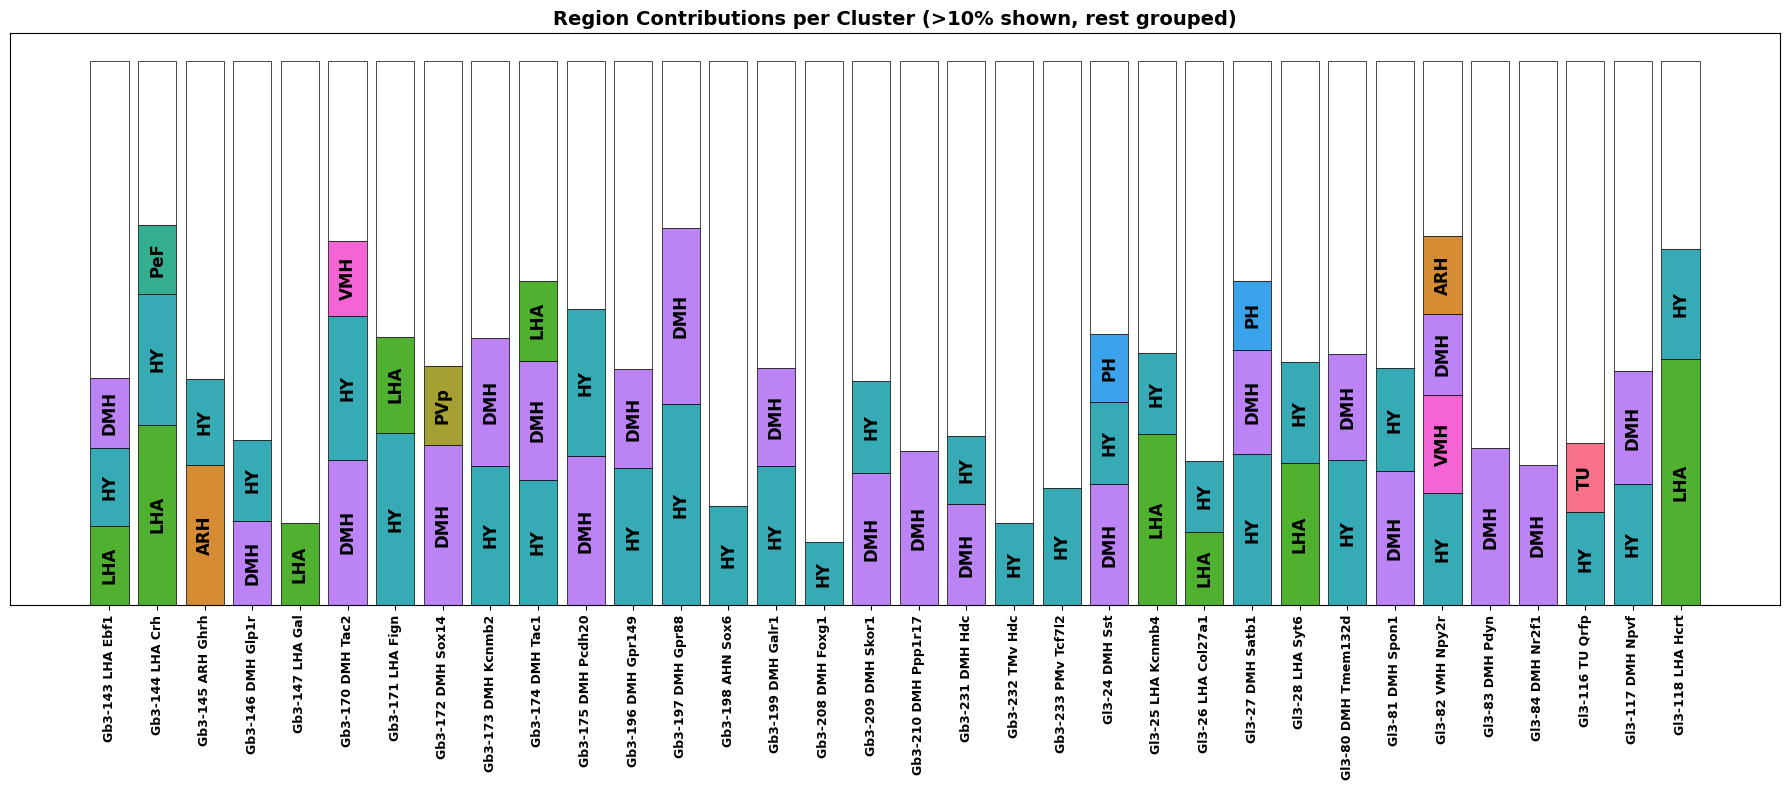

In [21]:

# Create figure and axis
fig, ax = plt.subplots(figsize=(18, 8))

# X positions
x = np.arange(len(clusters_region))

# Initialize bottom stack
bottom = np.zeros(len(clusters_region))

# Plot manually per cluster with per-cluster sorting
for i, cluster in enumerate(clusters_region):
    # Get the values for this cluster
    values = df_region[cluster]

    # Separate rest row
    if "Regions with < 12.5%" in values:
        rest_val = values["Regions with < 12.5%"]
        values_no_rest = values.drop("Regions with < 12.5%")
    else:
        rest_val = 0
        values_no_rest = values

    # Sort remaining regions by descending value
    values_sorted = values_no_rest.sort_values(ascending=False)

    # Now add the rest row at the end
    if rest_val > 0:
        values_sorted["Regions with < 12.5%"] = rest_val

    # Plot each region
    for region in values_sorted.index:
        height = values_sorted[region]
        if height > 0:
            ax.bar(
                x[i], height,
                bottom=bottom[i],
                color=color_map_region[region],
                edgecolor='black',
                linewidth=0.5,
                width=0.8
            )

            # Annotate if not "rest" and tall enough
            if region != "Regions with < 12.5%" and height > 3:
                ax.text(
                    x[i], bottom[i] + height / 2, region,
                    ha='center', va='center',
                    rotation=90,
                    fontsize=12,
                    fontweight='bold',
                    color='black',
                    clip_on=True
                )

            # Update bottom
            bottom[i] += height

# ---- Aesthetics ----
ax.set_xticks(x)
ax.set_xticklabels(clusters_region, rotation=90, ha='center', fontsize=9, weight='bold')
ax.set_yticks([])
ax.set_ylabel("")
ax.set_xlabel("")


plt.title("Region Contributions per Cluster (>10% shown, rest grouped)", fontsize=14, weight='bold')
plt.tight_layout()
plt.show()


### spatial QC

In [ ]:
warnings = relmass.loc[relmass.celltype_descr.isin(labelmat.L3_descr), ["celltype_descr", "flag"]]
warnings.flag = warnings.flag.fillna("None")

In [23]:
warnings.head(2)

,celltype_descr,flag
107,Gb3-143 LHA Ebf1,None
108,Gb3-144 LHA Crh,None


In [ ]:
color_map_warning_cat = {

  "None": "#155b0c",
  "Shape": "#C3C400",
  "Signal": "#EFC400",
  "Signal and shape": "#FF9E00",
  "No cells": "#FF4100",

    } 

In [ ]:
# Step 1: Get the warning categories for selected clusters AND sort to match leaf_labels_gsx order
category_warning = warnings.set_index("celltype_descr").loc[leaf_labels_supertype, "flag"]

# Step 2: Convert to categorical and drop unused categories
warning_categories = category_warning.astype("category").cat.remove_unused_categories()

# Step 3: Get numeric codes
category_codes_warning = warning_categories.cat.codes

# Step 4: Build 1-row heatmap input — now columns are correctly ordered
heatmap_warning = pd.DataFrame([category_codes_warning.values], columns=leaf_labels_supertype)

# Step 5: Get correct category order (used categories only)
category_order_warning = warning_categories.cat.categories

# Step 6: Build colormap
cmap_warning = ListedColormap([color_map_warning_cat[c] for c in category_order_warning])

# Reverse x-axis (column) order
heatmap_warning = heatmap_warning[heatmap_warning.columns[::-1]]


/tmp/ipykernel_3185603/3920754635.py:24: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


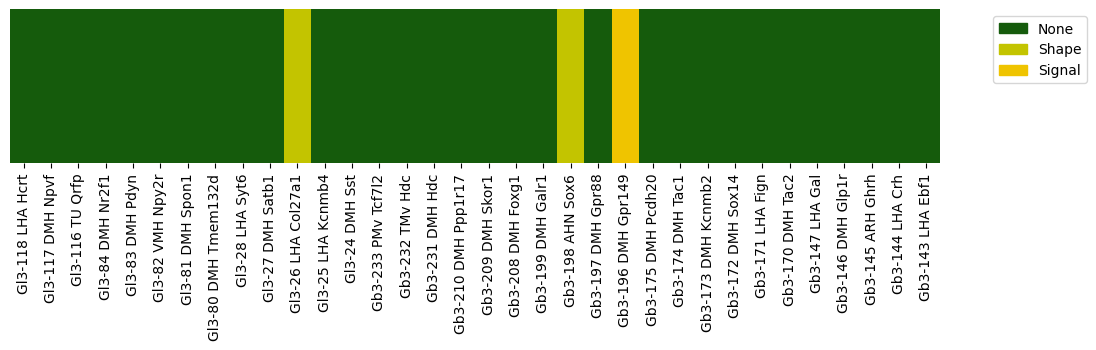

In [26]:

# Step 7: Plot
plt.figure(figsize=(12, 2))
sns.heatmap(
    heatmap_warning,
    cmap=cmap_warning,
    cbar=False,
    xticklabels=True,
    yticklabels=False
)

# Optional legend
import matplotlib.patches as mpatches
legend_handles = [
    mpatches.Patch(color=color_map_warning_cat[c], label=c)
    for c in category_order_warning
]
plt.legend(
    handles=legend_handles,
    bbox_to_anchor=(1.05, 1),
    loc='upper left',
    #title='HM3D to ABC Supertypes Mapping Category'
)

plt.tight_layout()
plt.show()


# Combining the above

## Vertical

/tmp/ipykernel_3185603/1982616560.py:165: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


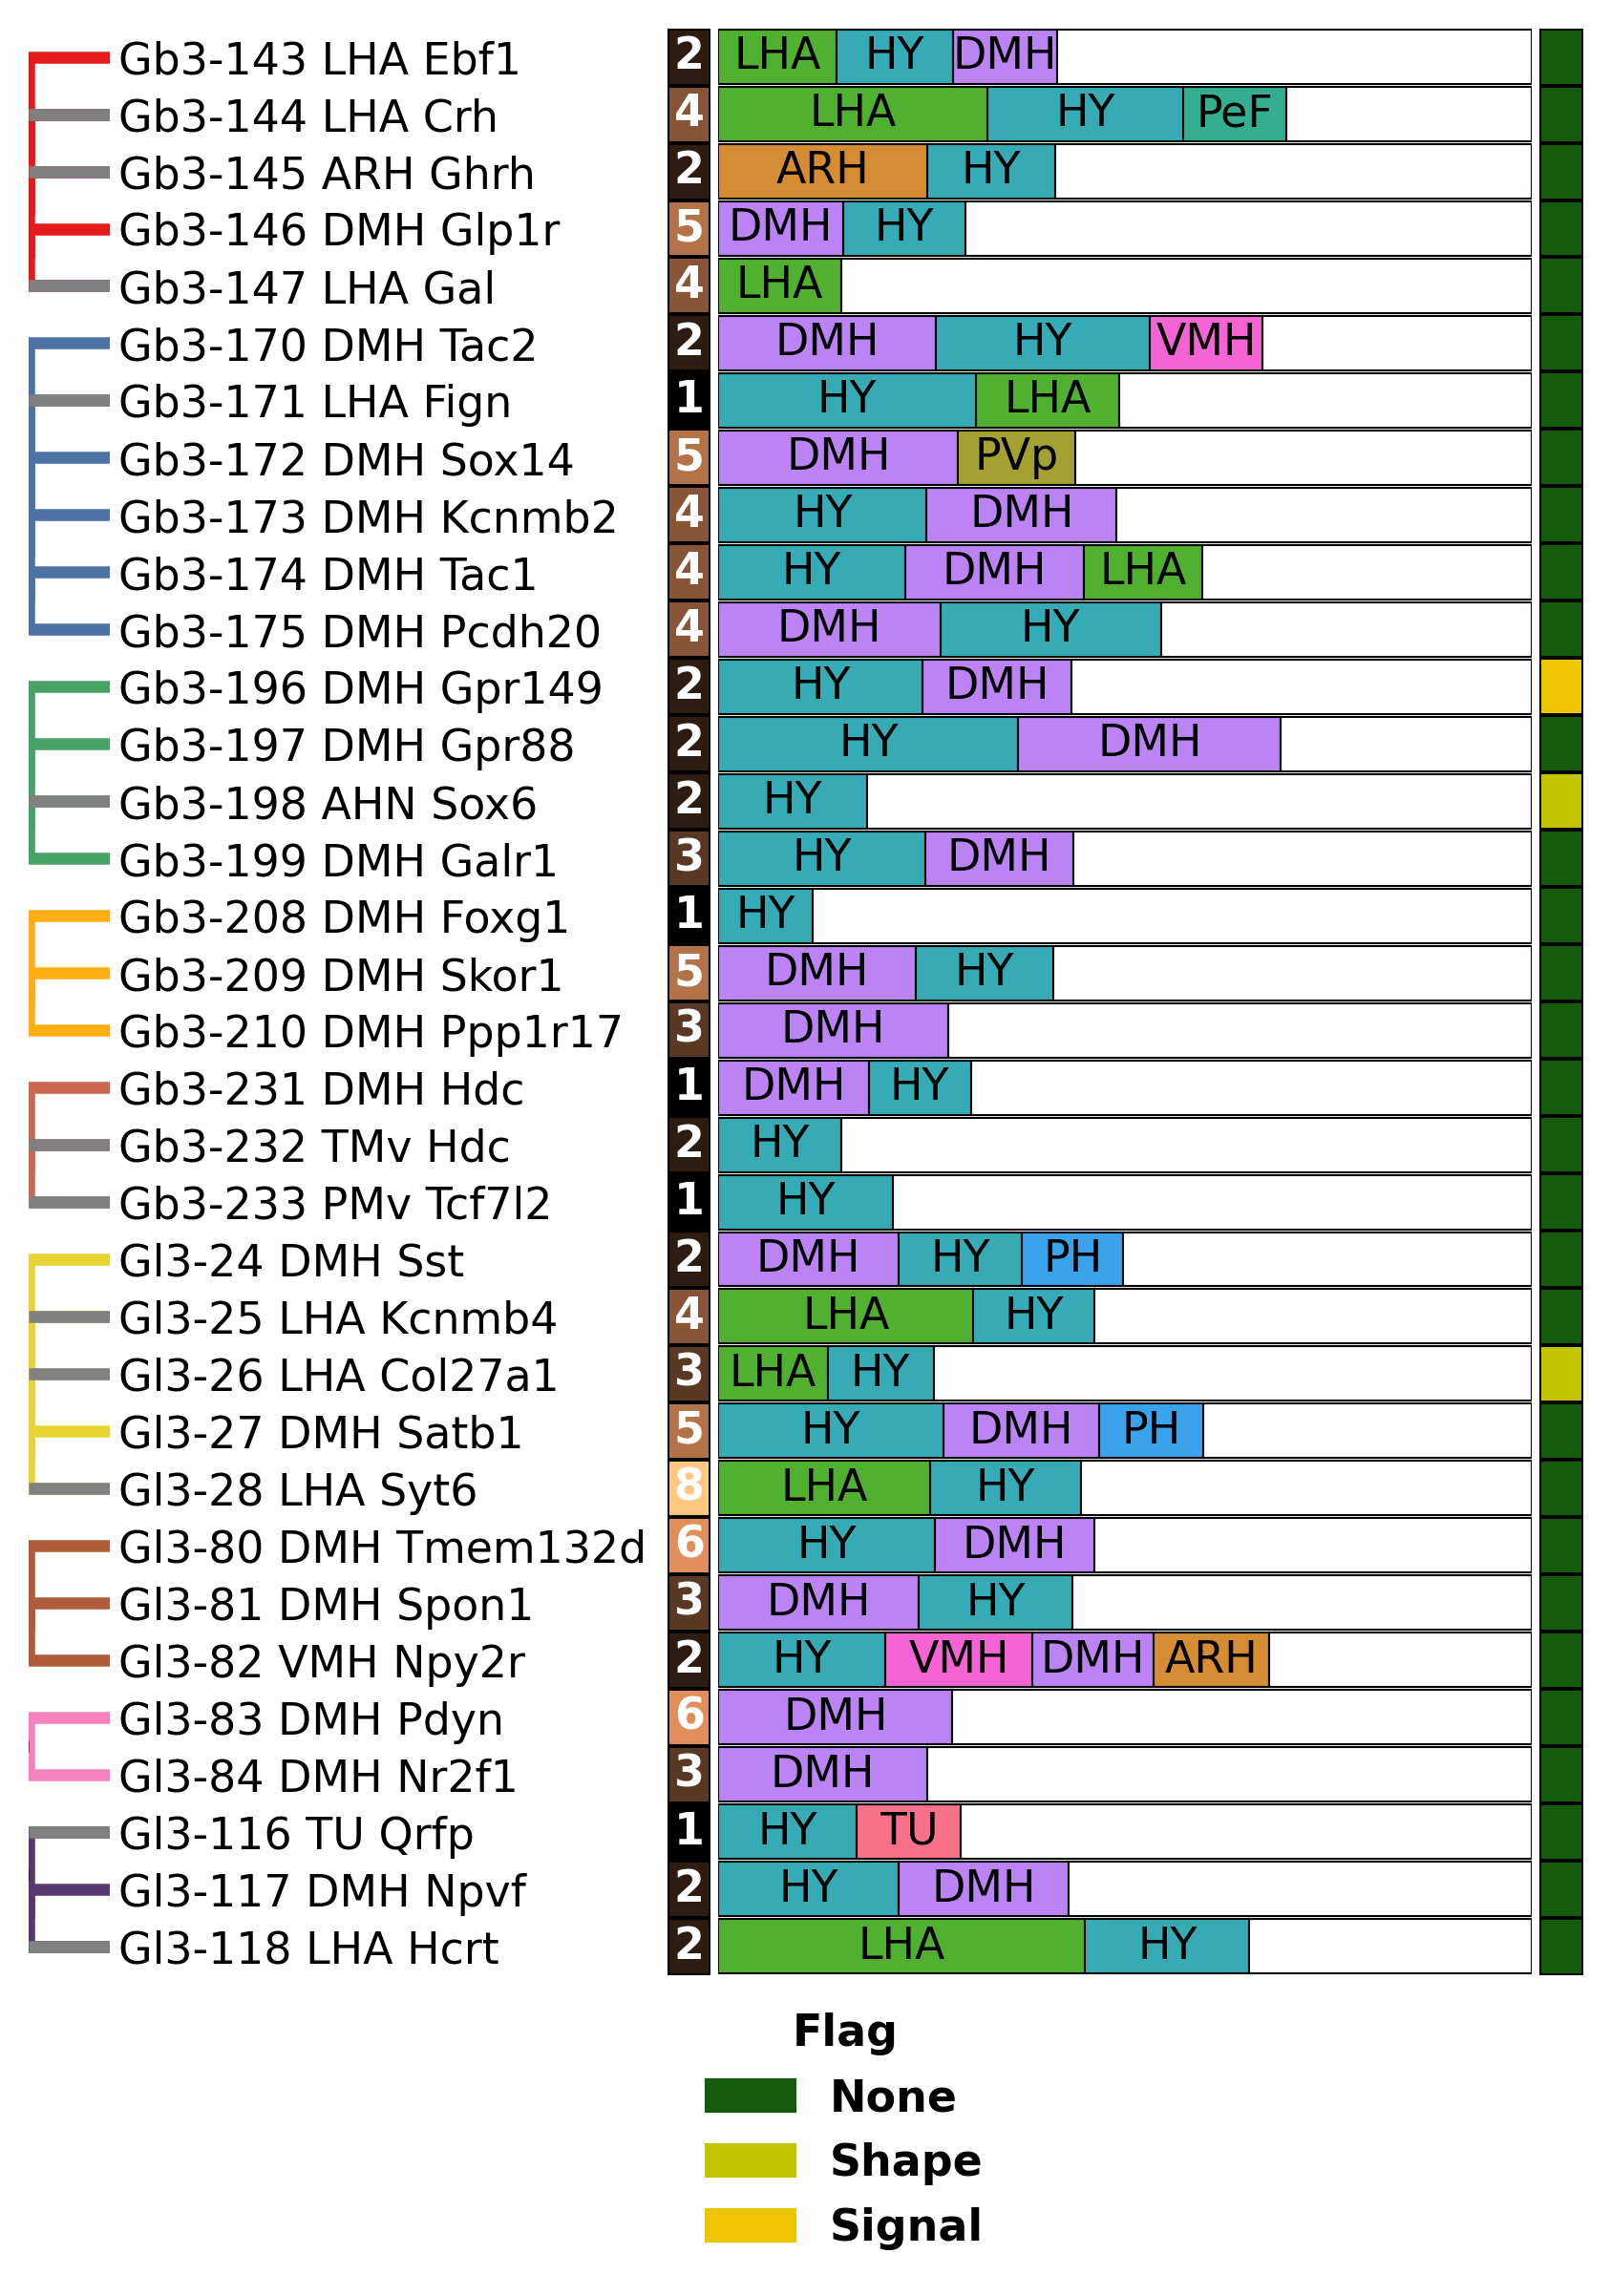

In [42]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import numpy as np
from matplotlib.patches import Patch

fontsize=11

# ==== CONFIG ====
fig = plt.figure(figsize=(7, 10), dpi=300)

leaf_labels = leaf_labels_supertype[::-1]  # Ensure this is precomputed
y = list(range(len(leaf_labels)))   # Swapped from x -> y for horizontal layout

gs = gridspec.GridSpec(
    nrows=2, ncols=5,
    width_ratios=[0.15, 1, 0.08, 1.5,  0.08,],
    height_ratios=[0.95, 0.1],
    hspace=0.05, wspace=0.025
)

# ===================== 1. Dendrogram =====================
ax_dendro = fig.add_subplot(gs[0, 0])
dendro = plot_colored_dendrogram(Z_supertype, idx_to_l3, l3_to_color, linewidth=3, ax=ax_dendro, orientation='left')
ax_dendro.set_yticklabels(leaf_labels, fontsize=fontsize, #fontweight='bold', 
    rotation=0)
ax_dendro.set_xlim(0.35, 0.2)
ax_dendro.tick_params(axis='y', pad=2, length=0) 
sns.despine(ax=ax_dendro, left=True, bottom=True)
ax_dendro.set_xticks([])
ax_dendro.set_ylabel("")
ax_dendro.set_xlabel("")

tick_labels = [tick.get_text() for tick in ax_dendro.get_yticklabels()]
tick_positions = ax_dendro.get_yticks()
label_to_y = dict(zip(tick_labels, tick_positions))

for label in label_to_y.keys():
    if label not in dmh_clusters_l3:
        plt.hlines(y=label_to_y[label], 
                xmin = 0, xmax=0.3,
                color="grey", linestyle='-', linewidth=3)

ax_dendro.set_xlim(0.3, 0)
#ax_dendro.set_yticks([])

# ===================== 2. Number of Subclusters Heatmap =====================
ax_num_subclusters = fig.add_subplot(gs[0, 2])
heat_data = heatmap_data_num_sub[leaf_labels[::-1]].T  # Transposed
sns.heatmap(
    heat_data,
    cmap="copper",
    cbar=False,
    xticklabels=False,
    yticklabels=True,
    linewidths=0.5,
    linecolor='black',
    ax=ax_num_subclusters,
    annot=True,
    fmt="d",
    annot_kws={"fontsize": fontsize, "weight": "bold", "color": "white", "va": "center", "ha": "center"}
)
ax_num_subclusters.set_xticks([])
ax_num_subclusters.set_yticks([])
ax_num_subclusters.set_ylabel("")
sns.despine(ax=ax_num_subclusters, left=True, bottom=True)

# ===================== 4. Region Contribution =====================
ax_region = fig.add_subplot(gs[0, 3])
bottom = np.zeros(len(leaf_labels[::-1]))

for i, cluster in enumerate(leaf_labels):
    values = df_region[cluster]
    rest = values.get("Regions with < 12.5%", 0)
    values_no_rest = values.drop("Regions with < 12.5%", errors="ignore")
    values_sorted = values_no_rest.sort_values(ascending=False)

    if rest > 0:
        values_sorted["Regions with < 12.5%"] = rest

    for region in values_sorted.index:
        width = values_sorted[region]
        if width > 0:
            ax_region.barh(
                y[i], width,
                left=bottom[i],
                height=0.95,
                color=color_map_region[region],
                edgecolor='black',
                linewidth=0.5
            )
            #if region != "Regions with < 10%" and width > 3:
            if region != "Regions with < 12.5%" and width >= 10:
                ax_region.text(
                    bottom[i] + width / 2, y[i], region,
                    ha='center', va='center',
                    rotation=0,
                    fontsize=fontsize,
                    #fontweight='bold'
                )

            elif region != "Regions with < 12.5%":
                ax_region.text(
                    bottom[i] + width / 2, y[i], region,
                    ha='center', va='center',
                    rotation=0,
                    fontsize=fontsize,
                    #fontweight='bold'
                    )
            bottom[i] += width

ax_region.set_ylim(-0.5, len(leaf_labels) - 0.5)
ax_region.margins(x=0)          # no padding left/right
ax_region.set_xlim(0, 100)      # optional: pin it explicitly if bars sum to 100
ax_region.set_yticks([])  # Remove default left-side labels
ax_region.set_xticks([])
sns.despine(ax=ax_region, left=True, bottom=True)

# ===================== 5. Warning Category Heatmap =====================
ax_warning = fig.add_subplot(gs[0, 4])
sns.heatmap(
    heatmap_warning.T.loc[leaf_labels[::-1]],  # ensure correct order
    cmap=cmap_warning,
    cbar=False,
    xticklabels=True,
    yticklabels=False,
    linewidths=0.5,
    linecolor='black',
    ax=ax_warning
)
ax_warning.set_ylabel("")
ax_warning.set_xlabel("")
ax_warning.set_xticks([])
sns.despine(ax=ax_warning, left=True, bottom=True)

# ===================== Warning Category Legend =====================
import matplotlib.patches as mpatches

ax_warning_leg = fig.add_subplot(gs[1, 2])
ax_warning_leg.axis("off")

legend_handles = [
    mpatches.Patch(color=color_map_warning_cat[c], label=c)
    for c in category_order_warning
]

ax_warning_leg.legend(
    handles=legend_handles,
    title="Flag",
    loc="center left",
    frameon=False,
    fontsize=fontsize,
    title_fontsize=fontsize
)


# ===================== Final Formatting =====================
for leg_ax in [ ax_warning_leg]:
    legend = leg_ax.get_legend()
    if legend:
        legend.get_title().set_fontweight('bold')
        for text in legend.get_texts():
            text.set_fontweight('bold')

plt.tight_layout()
plt.savefig(OUTDIR / "3b_clusterinfo_supertype_tree_vertical.pdf", dpi=300, bbox_inches="tight")
plt.show()
